Dataset : iris from Sckit-learn we will use the build in iris dataset. it contains measurements fo iris flowers. Feature Meaning


*   sepal length : width of the sepal

*   petal length : Length of the petal

*   petal width : Width of the petal

* target : Flower Species

The Original dataset has three species, Setosa, Versicolor and Virginica, For Our first example, we will select two species only to make it a binary classification problem



*   0 = Setosa
*   1 = Versicolor




In [1]:
import pandas as pd
import numpy as np

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ( accuracy_score, classification_report, confusion_matrix)

import matplotlib.pyplot as plt
import seaborn as sns

# Load the Iris Dataset

iris = load_iris()

#Convert featrues inoto a dataFrame
df = pd.DataFrame(iris.data, columns=iris.feature_names)

# Add the target column
df['target'] = iris.target

#Display the first five rows
print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  


In [2]:
print("Dataset shape:", df.shape)
print("Column names:", df.columns)
print("Target classes:", iris.target_names)
print(df.info())

Dataset shape: (150, 5)
Column names: Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'target'],
      dtype='object')
Target classes: ['setosa' 'versicolor' 'virginica']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB
None


In [3]:
#Keep only target classes 0 = 1
df = df[df["target"]!=2]

print(df.head())
print(df["target"].value_counts())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  
target
0    50
1    50
Name: count, dtype: int64


The Original target lables are:

Target Species

0: Setosa

1: Versicolor

2: Virginica - removed

After Filtering, we have 100 samples: 50 from each of the two selected species


In [4]:
# Input features

X = df.drop("target", axis=1)

#Output variable
y = df["target"]

print("Input shape:", X.shape)
print("Output shape:", y.shape)

print(X.head())
print(y.head())

Input shape: (100, 4)
Output shape: (100,)
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64


In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training samples", X_train.shape[0])
print("Testing samples", X_test.shape[0])

Training samples 80
Testing samples 20


In [6]:
scaler = StandardScaler()

# Learn scaling parameters from training data
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same tranformation to test data
X_test_scaled = scaler.transform(X_test)

Important: We use fit_transform() on training data only transform() on test data. This prevents information from the test set leaking into the training process.

In [7]:
# Create the model
model = LogisticRegression()

# Train the model
model.fit(X_train_scaled, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test_scaled)

print("Actual values:")
print(y_test.values)

print("Predicted values:")
print(y_pred)

Actual values:
[1 1 1 1 0 0 0 1 0 0 0 1 0 0 0 1 1 0 1 1]
Predicted values:
[1 1 1 1 0 0 0 1 0 0 0 1 0 0 0 1 1 0 1 1]


Fo each test sample, the model predicts either:

* 0 - Setosa
* 1 - Versicolor

A prediction matching the actual target is correct; a mismatch is an incorrect prediction.

In [8]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Model Accuracy(%):", accuracy*100)



Model Accuracy: 1.0
Model Accuracy(%): 100.0


Confusion Matrix:
[[10  0]
 [ 0 10]]


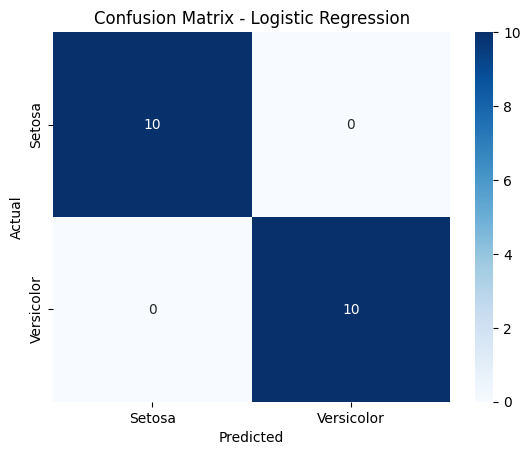

In [9]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Setosa", "Versicolor"],
    yticklabels=["Setosa", "Versicolor"],
    cmap="Blues"
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

In [10]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Setosa", "Versicolor"]
))

              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        10
  Versicolor       1.00      1.00      1.00        10

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



The report provides:
* Precision: of the samples predicted as a class, how many actually belong to that class
* Recall: Of the samples actually belonging to a class, how may did the model correctly identify?
* F1-score: The harmonic mean of precision and recall
* Support: The number of actual test samples in each class.

In [11]:
# New flower measurements in the same feature order
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)

#Apply the training scaler (Standardizing)
new_flower_scaled = scaler.transform(new_flower)

# Predict the class
prediction = model.predict(new_flower_scaled)

# Predict Class propbabilites

probabilites = model.predict_proba(new_flower_scaled)

# Print the prediction

if prediction[0] == 0:
  print("Predicted species: Setosa")
else:
  print("Predicted species: Versicolor")

print("Class Probabilites:", probabilites)

Predicted species: Setosa
Class Probabilites: [[0.98581743 0.01418257]]


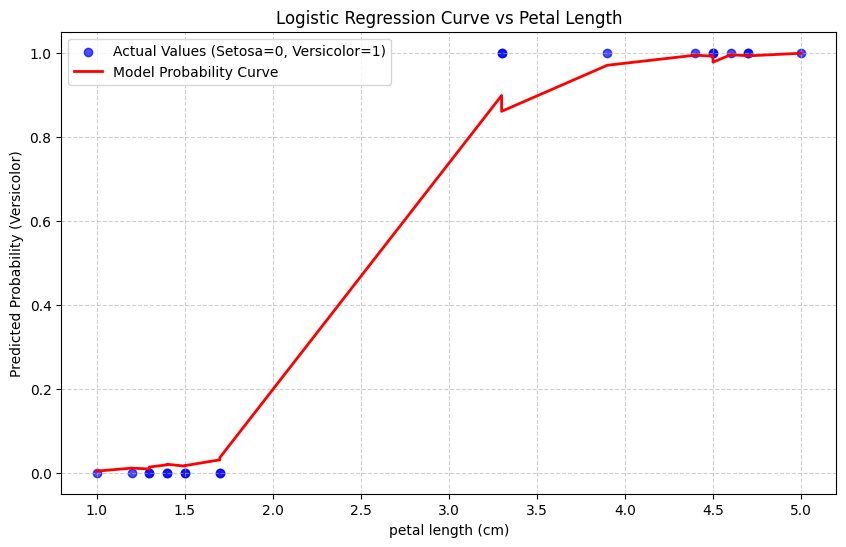

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# We have 4 features, let's select 'petal length (cm)' for 1D visualization
# and plot predicted probabilities against it.

# Get 'petal length (cm)' index in the original columns (index 2)
feature_name = "petal length (cm)"
feature_idx = list(X.columns).index(feature_name)

# Extract the feature values from the test set
x_feature = X_test[feature_name]

# Predict probabilities using the scaled test set
y_prob = model.predict_proba(X_test_scaled)[:, 1]

# Sort the values for a smooth line plot
sort_idx = np.argsort(x_feature)
x_feature_sorted = x_feature.iloc[sort_idx]
y_prob_sorted = y_prob[sort_idx]

plt.figure(figsize=(10, 6))
# Plot the actual outcomes
plt.scatter(x_feature, y_test, color='blue', alpha=0.7, label="Actual Values (Setosa=0, Versicolor=1)")
# Plot the logistic regression curve (probabilities)
plt.plot(x_feature_sorted, y_prob_sorted, color="red", linewidth=2, label="Model Probability Curve")

plt.xlabel(f"{feature_name}")
plt.ylabel("Predicted Probability (Versicolor)")
plt.title("Logistic Regression Curve vs Petal Length")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()